# TA Pengolahan Citra 125 — versi Colab (semua dalam satu notebook)
**Mean vs Gaussian vs Median Filter untuk Reduksi Noise**

Cara pakai: **Runtime → Run all**. Total sekitar 6–10 menit. Notebook ini menulis semua kode sendiri, mengunduh 104 citra, menjalankan eksperimen, lalu menyiapkan ZIP hasil untuk diunduh.

## 1. Persiapan
Sel ini memasang Drive (jika di Colab), menentukan folder kerja dengan alamat lengkap (aman dijalankan berulang), dan memasang pustaka.

In [1]:
import os
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False
# Komputasi dikerjakan di disk lokal Colab (cepat dan stabil); salinan ke Drive dilakukan di bagian 7.
BASE = '/content/TA_PengolahanCitra125' if EN_COLAB else os.path.abspath('proj')
os.makedirs(BASE + '/src', exist_ok=True)
os.chdir(BASE)
!pip -q install openpyxl scikit-image opencv-python-headless
print('folder kerja:', os.getcwd())

folder kerja: /content/TA_PengolahanCitra125


## 2. Kode program
Enam berkas berikut ditulis ke folder kerja. **Jangan diubah** agar hasil sama dengan laporan.
- `src/citra.py` — pustaka inti (prapemrosesan, noise, filter, metrik)
- `unduh_dataset.py`, `run_experiment.py`, `analyze.py`, `buat_gambar.py`, `buat_xlsx.py`

In [2]:
%%writefile src/citra.py
"""
citra.py - Pustaka inti Tugas Akhir Pengolahan Citra 125
Perbandingan Mean, Gaussian, dan Median Filter untuk Reduksi Noise.

Isi:
  - pemuatan dataset + metadata
  - prapemrosesan (RGB -> grayscale, normalisasi, resize)
  - pembangkit noise (Gaussian aditif, salt-and-pepper)
  - filter: implementasi OpenCV (cepat) dan implementasi dari nol (NumPy)
  - metrik: PSNR, SSIM, MAE, F1 tepi (Canny)
"""
import glob
import os
import time

import cv2
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# --------------------------------------------------------------------------
# 1. Dataset
# --------------------------------------------------------------------------
SUMBER = {
    "BSD68": "Berkeley Segmentation Dataset (BSDS300), subset uji 68 citra (Martin dkk., 2001)",
    "Set12": "Set12, 12 citra uji baku denoising (Zhang dkk., 2017)",
    "Kodak24": "Kodak Lossless True Color Image Suite, 24 citra (Eastman Kodak)",
}


def daftar_citra(root):
    """Mengembalikan daftar (kelompok, nama_berkas, path) terurut."""
    hasil = []
    for kel in ["BSD68", "Set12", "Kodak24"]:
        for p in sorted(glob.glob(os.path.join(root, kel, "*.png"))):
            hasil.append((kel, os.path.basename(p), p))
    return hasil


def muat_asli(path):
    """Membaca citra apa adanya (tanpa konversi) beserta metadata."""
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        raise IOError(f"Gagal membaca {path}")
    meta = {
        "tinggi": img.shape[0],
        "lebar": img.shape[1],
        "kanal": 1 if img.ndim == 2 else img.shape[2],
        "dtype": str(img.dtype),
        "ukuran_berkas_kb": round(os.path.getsize(path) / 1024, 1),
    }
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img, meta


# --------------------------------------------------------------------------
# 2. Prapemrosesan
# --------------------------------------------------------------------------
def ke_grayscale(img):
    """RGB -> grayscale (bobot ITU-R BT.601: 0,299 R + 0,587 G + 0,114 B)."""
    if img.ndim == 2:
        return img.copy()
    return cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)


def normalisasi(gray_u8):
    """uint8 [0,255] -> float32 [0,1]."""
    return gray_u8.astype(np.float32) / 255.0


def denormalisasi(x):
    """float [0,1] -> uint8 (clip + pembulatan)."""
    return np.clip(np.rint(x * 255.0), 0, 255).astype(np.uint8)


def ubah_ukuran(img, sisi):
    """Resize ke sisi x sisi (INTER_AREA untuk mengecil, INTER_LINEAR untuk membesar)."""
    h, w = img.shape[:2]
    inter = cv2.INTER_AREA if sisi < min(h, w) else cv2.INTER_LINEAR
    return cv2.resize(img, (sisi, sisi), interpolation=inter)


# --------------------------------------------------------------------------
# 3. Pembangkit noise
# --------------------------------------------------------------------------
def noise_gaussian(gray_u8, sigma, rng):
    """Noise Gaussian aditif, rerata 0, simpangan baku `sigma` (skala 0-255)."""
    x = normalisasi(gray_u8)
    x = x + rng.normal(0.0, sigma / 255.0, size=x.shape).astype(np.float32)
    return denormalisasi(x)


def noise_salt_pepper(gray_u8, kerapatan, rng):
    """Salt-and-pepper: `kerapatan` = proporsi piksel rusak (separuh 0, separuh 255)."""
    out = gray_u8.copy()
    r = rng.random(out.shape)
    out[r < kerapatan / 2] = 0
    out[(r >= kerapatan / 2) & (r < kerapatan)] = 255
    return out


KONDISI_NOISE = [
    ("G10", "Gaussian", 10),
    ("G25", "Gaussian", 25),
    ("G50", "Gaussian", 50),
    ("SP05", "Salt-pepper", 0.05),
    ("SP15", "Salt-pepper", 0.15),
    ("SP30", "Salt-pepper", 0.30),
]


def beri_noise(gray_u8, kode, rng):
    for k, jenis, par in KONDISI_NOISE:
        if k == kode:
            if jenis == "Gaussian":
                return noise_gaussian(gray_u8, par, rng)
            return noise_salt_pepper(gray_u8, par, rng)
    raise KeyError(kode)


# --------------------------------------------------------------------------
# 4. Filter - implementasi OpenCV
# --------------------------------------------------------------------------
def filter_cv(img, metode, k):
    if metode == "Mean":
        return cv2.blur(img, (k, k), borderType=cv2.BORDER_REFLECT_101)
    if metode == "Gaussian":
        # sigma=0 -> OpenCV memakai sigma = 0.3*((k-1)*0.5 - 1) + 0.8
        return cv2.GaussianBlur(img, (k, k), 0, borderType=cv2.BORDER_REFLECT_101)
    if metode == "Median":
        return cv2.medianBlur(img, k)
    raise KeyError(metode)


def sigma_otomatis(k):
    """Rumus sigma OpenCV untuk k > 7 (saat sigma=0): 0.3*((k-1)*0.5 - 1) + 0.8."""
    return 0.3 * ((k - 1) * 0.5 - 1) + 0.8


def kernel_gaussian_cv(k):
    """Kernel 1D yang benar-benar dipakai OpenCV saat sigma=0.
    Untuk k = 3, 5, 7 OpenCV memakai tabel koefisien tetap (mendekati binomial);
    untuk k > 7 memakai fungsi Gaussian dengan sigma_otomatis(k)."""
    return cv2.getGaussianKernel(k, 0).ravel()


def sigma_efektif(k):
    """Simpangan baku efektif kernel 1D yang dipakai OpenCV (sigma=0)."""
    w = kernel_gaussian_cv(k)
    x = np.arange(k) - (k - 1) / 2.0
    return float(np.sqrt(np.sum(w * x ** 2)))


# --------------------------------------------------------------------------
# 5. Filter - implementasi dari nol (NumPy), untuk verifikasi
# --------------------------------------------------------------------------
def kernel_gaussian(k, sigma):
    ax = np.arange(k) - (k - 1) / 2.0
    g = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    K = np.outer(g, g)
    return K / K.sum()


def filter_manual(img_u8, metode, k, sigma=None):
    """Konvolusi/rank-filter 2D manual.
    Perilaku batas disamakan dengan OpenCV agar dapat dibandingkan piksel demi piksel:
      Mean/Gaussian -> pantulan (BORDER_REFLECT_101 = np.pad 'reflect')
      Median        -> replikasi tepi (cv2.medianBlur hanya mendukung BORDER_REPLICATE)
    Gaussian tanpa `sigma` memakai kernel 1D yang sama dengan OpenCV (sigma=0)."""
    r = k // 2
    mode = "edge" if metode == "Median" else "reflect"
    pad = np.pad(img_u8.astype(np.float64), r, mode=mode)
    jendela = sliding_window_view(pad, (k, k))          # (H, W, k, k)
    if metode == "Mean":
        out = jendela.mean(axis=(2, 3))
    elif metode == "Gaussian":
        if sigma:
            K = kernel_gaussian(k, sigma)
        else:
            g1 = kernel_gaussian_cv(k)
            K = np.outer(g1, g1)
        out = np.einsum("hwij,ij->hw", jendela, K)
    elif metode == "Median":
        out = np.median(jendela.reshape(*jendela.shape[:2], -1), axis=2)
    else:
        raise KeyError(metode)
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


# --------------------------------------------------------------------------
# 6. Metrik evaluasi
# --------------------------------------------------------------------------
def psnr(ref, uji):
    return float(peak_signal_noise_ratio(ref, uji, data_range=255))


def ssim(ref, uji):
    return float(structural_similarity(ref, uji, data_range=255))


def mae(ref, uji):
    return float(np.mean(np.abs(ref.astype(np.int16) - uji.astype(np.int16))))


def ambang_canny(ref):
    """Ambang Canny otomatis dari citra bersih: 0,66*median dan 1,33*median intensitas."""
    v = float(np.median(ref))
    return int(max(0, 0.66 * v)), int(min(255, 1.33 * v))


def f1_tepi(ref, uji, ambang):
    """F1 peta tepi Canny(uji) terhadap Canny(ref), toleransi 1 piksel."""
    lo, hi = ambang
    e_ref = cv2.Canny(ref, lo, hi) > 0
    e_uji = cv2.Canny(uji, lo, hi) > 0
    if e_ref.sum() == 0 or e_uji.sum() == 0:
        return 0.0, 0.0, 0.0
    se = np.ones((3, 3), np.uint8)
    d_ref = cv2.dilate(e_ref.astype(np.uint8), se) > 0
    d_uji = cv2.dilate(e_uji.astype(np.uint8), se) > 0
    presisi = (e_uji & d_ref).sum() / e_uji.sum()
    recall = (e_ref & d_uji).sum() / e_ref.sum()
    f1 = 0.0 if presisi + recall == 0 else 2 * presisi * recall / (presisi + recall)
    return float(presisi), float(recall), float(f1)


def kekuatan_detail(gray_u8):
    """Rerata magnitudo gradien Sobel (indikator tingkat detail/tekstur citra)."""
    gx = cv2.Sobel(gray_u8, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray_u8, cv2.CV_32F, 0, 1, ksize=3)
    return float(np.mean(np.hypot(gx, gy)))


def waktu_ms(fungsi, ulang=5):
    """Median waktu eksekusi (ms) dari `ulang` pengulangan."""
    t = []
    for _ in range(ulang):
        a = time.perf_counter()
        fungsi()
        t.append((time.perf_counter() - a) * 1000.0)
    return float(np.median(t))


Writing src/citra.py


In [3]:
%%writefile unduh_dataset.py
"""
unduh_dataset.py - Mengunduh dataset publik yang dipakai pada proyek ini.

Sumber (semua citra dipakai hanya untuk keperluan pembelajaran/penelitian non-komersial):
  BSD68   : subset uji 68 citra dari Berkeley Segmentation Dataset (BSDS300).
            Martin dkk., ICCV 2001. https://www2.eecs.berkeley.edu/Research/Projects/CS/vision/bsds/
  Set12   : 12 citra uji baku denoising (Zhang dkk., IEEE TIP 2017).
  Kodak24 : Kodak Lossless True Color Image Suite (Eastman Kodak), 24 citra; versi
            potongan 500x500 piksel yang dipakai pada benchmark denoising.
Salinan berkas diambil dari repositori uji milik penulis DnCNN/FFDNet:
  https://github.com/cszn/DnCNN  dan  https://github.com/cszn/FFDNet
Penggunaan:  python unduh_dataset.py
"""
import os
import urllib.request

ROOT = os.path.join(os.path.dirname(os.path.abspath(__file__)), "data")
BASE = "https://raw.githubusercontent.com/cszn"
DAFTAR = [
    ("BSD68", f"{BASE}/DnCNN/master/testsets/BSD68/test{{:03d}}.png", range(1, 69)),
    ("Set12", f"{BASE}/DnCNN/master/testsets/Set12/{{:02d}}.png", range(1, 13)),
    ("Kodak24", f"{BASE}/FFDNet/master/testsets/Kodak24/kodim{{:02d}}.png", range(1, 25)),
]

for kel, pola, rentang in DAFTAR:
    os.makedirs(os.path.join(ROOT, kel), exist_ok=True)
    for i in rentang:
        url = pola.format(i)
        tujuan = os.path.join(ROOT, kel, os.path.basename(url))
        if os.path.exists(tujuan):
            continue
        urllib.request.urlretrieve(url, tujuan)
    print(kel, "->", len(os.listdir(os.path.join(ROOT, kel))), "berkas")
print("Selesai. Total harus 104 citra (68 + 12 + 24).")


Writing unduh_dataset.py


In [4]:
%%writefile run_experiment.py
"""
run_experiment.py - Menjalankan seluruh eksperimen Tugas Akhir Pengolahan Citra 125.

Keluaran (folder results/):
  metadata_dataset.csv   : metadata tiap citra (sumber, dimensi, kanal, detail)
  hasil_utama.csv        : PSNR/SSIM/MAE/F1-tepi tiap (citra, noise, metode, kernel)
  waktu_proses.csv       : waktu proses per metode/kernel pada citra asli
  waktu_skala.csv        : waktu proses terhadap ukuran citra dan ukuran kernel
  sweep_sigma.csv        : pengaruh sigma Gaussian
  verifikasi_manual.csv  : beda implementasi dari nol vs OpenCV
Semua acak memakai seed tetap sehingga hasil dapat direproduksi.
"""
import os
import sys
import time

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "src"))
import citra as c  # noqa: E402

ROOT = os.path.dirname(os.path.abspath(__file__))
DATA = os.path.join(ROOT, "data")
OUT = os.path.join(ROOT, "results")
os.makedirs(OUT, exist_ok=True)

SEED = 2026
METODE = ["Mean", "Gaussian", "Median"]
KERNEL = [3, 5, 7, 9]

t0 = time.time()
daftar = c.daftar_citra(DATA)
print(f"Jumlah citra: {len(daftar)}", flush=True)

# ------------------------------------------------------------------ metadata
meta_rows, gray_cache = [], []
for idx, (kel, nama, path) in enumerate(daftar):
    asli, m = c.muat_asli(path)
    g = c.ke_grayscale(asli)
    gray_cache.append(g)
    meta_rows.append({
        "id": idx, "kelompok": kel, "berkas": nama, **m,
        "intensitas_rerata": round(float(g.mean()), 2),
        "kontras_std": round(float(g.std()), 2),
        "detail_sobel": round(c.kekuatan_detail(g), 2),
    })
meta = pd.DataFrame(meta_rows)
meta.to_csv(os.path.join(OUT, "metadata_dataset.csv"), index=False)
print(meta.groupby("kelompok").size().to_dict(), flush=True)

# ------------------------------------------------------------- eksperimen utama
rows = []
for idx, (kel, nama, path) in enumerate(daftar):
    ref = gray_cache[idx]
    amb = c.ambang_canny(ref)
    for ci, (kode, jenis, par) in enumerate(c.KONDISI_NOISE):
        rng = np.random.default_rng(SEED * 1000 + idx * 10 + ci)
        noisy = c.beri_noise(ref, kode, rng)
        base = dict(id=idx, kelompok=kel, berkas=nama, noise=kode, jenis=jenis, par=par)
        p, r_, f = c.f1_tepi(ref, noisy, amb)
        rows.append({**base, "metode": "Tanpa filter", "kernel": 0,
                     "psnr": c.psnr(ref, noisy), "ssim": c.ssim(ref, noisy),
                     "mae": c.mae(ref, noisy), "tepi_presisi": p, "tepi_recall": r_, "tepi_f1": f})
        for met in METODE:
            for k in KERNEL:
                out = c.filter_cv(noisy, met, k)
                p, r_, f = c.f1_tepi(ref, out, amb)
                rows.append({**base, "metode": met, "kernel": k,
                             "psnr": c.psnr(ref, out), "ssim": c.ssim(ref, out),
                             "mae": c.mae(ref, out), "tepi_presisi": p, "tepi_recall": r_,
                             "tepi_f1": f})
    if idx % 10 == 0:
        print(f"  utama: {idx + 1}/{len(daftar)}  ({time.time() - t0:.0f} dtk)", flush=True)
hasil = pd.DataFrame(rows)
hasil.to_csv(os.path.join(OUT, "hasil_utama.csv"), index=False)

# ------------------------------------------------------------------ waktu proses
# Dijalankan berurutan (tanpa paralelisme) pada kondisi G25.
wrows = []
for idx, (kel, nama, path) in enumerate(daftar):
    ref = gray_cache[idx]
    noisy = c.beri_noise(ref, "G25", np.random.default_rng(SEED * 1000 + idx * 10 + 1))
    for met in METODE:
        for k in KERNEL:
            wrows.append({"id": idx, "kelompok": kel, "metode": met, "kernel": k,
                          "mp": ref.size / 1e6,
                          "waktu_ms": c.waktu_ms(lambda: c.filter_cv(noisy, met, k), 3)})
pd.DataFrame(wrows).to_csv(os.path.join(OUT, "waktu_proses.csv"), index=False)
print(f"waktu selesai ({time.time() - t0:.0f} dtk)", flush=True)

# --------------------------------------------------- skala waktu (ukuran & kernel)
# Citra dasar: Kodak24 kodim01 (grayscale), di-resize ke berbagai sisi.
base = gray_cache[[i for i, d in enumerate(daftar) if d[1] == "kodim01.png"][0]]
srows = []
for sisi in [128, 256, 512, 1024, 2048]:
    im = c.ubah_ukuran(base, sisi)
    for met in METODE:
        for k in [3, 5, 7, 9, 11, 15]:
            srows.append({"implementasi": "OpenCV", "sisi": sisi, "metode": met, "kernel": k,
                          "waktu_ms": c.waktu_ms(lambda: c.filter_cv(im, met, k), 3)})
im = c.ubah_ukuran(base, 128)
for met in METODE:
    for k in [3, 5, 7, 9, 11]:
        srows.append({"implementasi": "Manual (NumPy)", "sisi": 128, "metode": met, "kernel": k,
                      "waktu_ms": c.waktu_ms(lambda: c.filter_manual(im, met, k), 2)})
pd.DataFrame(srows).to_csv(os.path.join(OUT, "waktu_skala.csv"), index=False)
print(f"skala selesai ({time.time() - t0:.0f} dtk)", flush=True)

# --------------------------------------------------------------- sweep sigma
srows = []
for idx, (kel, nama, path) in enumerate(daftar):
    ref = gray_cache[idx]
    noisy = c.beri_noise(ref, "G25", np.random.default_rng(SEED * 1000 + idx * 10 + 1))
    import cv2
    for sg in [0.5, 0.8, 1.0, 1.4, 2.0, 3.0]:
        out = cv2.GaussianBlur(noisy, (15, 15), sg, borderType=cv2.BORDER_REFLECT_101)
        srows.append({"id": idx, "sigma": sg, "psnr": c.psnr(ref, out), "ssim": c.ssim(ref, out)})
pd.DataFrame(srows).to_csv(os.path.join(OUT, "sweep_sigma.csv"), index=False)

# ------------------------------------------------- verifikasi implementasi manual
vrows = []
pilih = [0, 20, 68, 70, 80, 95]            # campuran BSD68, Set12, Kodak24
for idx in pilih:
    ref = c.ubah_ukuran(gray_cache[idx], 128)
    noisy = c.beri_noise(ref, "G25", np.random.default_rng(SEED + idx))
    for met in METODE:
        for k in [3, 5, 7]:
            a = c.filter_cv(noisy, met, k).astype(int)
            b = c.filter_manual(noisy, met, k).astype(int)
            vrows.append({"id": idx, "metode": met, "kernel": k,
                          "beda_maks": int(np.abs(a - b).max()),
                          "beda_rerata": float(np.abs(a - b).mean())})
pd.DataFrame(vrows).to_csv(os.path.join(OUT, "verifikasi_manual.csv"), index=False)
print(f"SELESAI total {time.time() - t0:.0f} dtk", flush=True)


Writing run_experiment.py


In [5]:
%%writefile analyze.py
"""
analyze.py - Meringkas hasil eksperimen, uji statistik, analisis kegagalan,
dan eksperimen tambahan pada citra berwarna (Kodak24).
Membaca results/*.csv, menulis results/ringkasan_*.csv
"""
import os
import sys

import numpy as np
import pandas as pd
from scipy import stats

sys.path.insert(0, os.path.join(os.path.dirname(__file__), "src"))
import citra as c  # noqa: E402

ROOT = os.path.dirname(os.path.abspath(__file__))
OUT = os.path.join(ROOT, "results")
H = pd.read_csv(os.path.join(OUT, "hasil_utama.csv"))
M = pd.read_csv(os.path.join(OUT, "metadata_dataset.csv"))
KODE = [k for k, _, _ in c.KONDISI_NOISE]

# ---------------------------------------------------------------- ringkasan umum
agg = (H.groupby(["noise", "metode", "kernel"])
         .agg(psnr=("psnr", "mean"), psnr_sd=("psnr", "std"),
              ssim=("ssim", "mean"), ssim_sd=("ssim", "std"),
              mae=("mae", "mean"), tepi_f1=("tepi_f1", "mean"),
              tepi_presisi=("tepi_presisi", "mean"), tepi_recall=("tepi_recall", "mean"),
              n=("psnr", "size"))
         .reset_index())
agg["noise"] = pd.Categorical(agg["noise"], KODE, ordered=True)
agg = agg.sort_values(["noise", "metode", "kernel"])
agg.to_csv(os.path.join(OUT, "ringkasan_semua_konfigurasi.csv"), index=False)

# konfigurasi terbaik (berdasar PSNR rerata) per kondisi x metode
idx = agg[agg.metode != "Tanpa filter"].groupby(["noise", "metode"], observed=True)["psnr"].idxmax()
best = agg.loc[idx].copy()
best["noise"] = best["noise"].astype(str)
base = agg[agg.metode == "Tanpa filter"].assign(noise=lambda d: d.noise.astype(str)).set_index("noise")
best["psnr_noisy"] = best["noise"].astype(str).map(base["psnr"]).astype(float)
best["ssim_noisy"] = best["noise"].astype(str).map(base["ssim"]).astype(float)
best["tepi_f1_noisy"] = best["noise"].astype(str).map(base["tepi_f1"]).astype(float)
best["gain_psnr"] = best["psnr"] - best["psnr_noisy"]
best.to_csv(os.path.join(OUT, "ringkasan_terbaik.csv"), index=False)

# ----------------------------------------------------------- uji statistik berpasangan
rows = []
for kode in KODE:
    sub = H[H.noise == kode]
    bm = {m: int(best[(best.noise == kode) & (best.metode == m)].kernel.iloc[0])
          for m in ["Mean", "Gaussian", "Median"]}
    get = {m: sub[(sub.metode == m) & (sub.kernel == bm[m])].sort_values("id")["psnr"].values
           for m in bm}
    for a, b in [("Median", "Gaussian"), ("Median", "Mean"), ("Gaussian", "Mean")]:
        d = get[a] - get[b]
        try:
            p = stats.wilcoxon(get[a], get[b]).pvalue
        except ValueError:
            p = np.nan
        rows.append({"noise": kode, "A": f"{a} (k={bm[a]})", "B": f"{b} (k={bm[b]})",
                     "selisih_psnr_rerata": d.mean(), "A_lebih_baik_pada_%": 100 * (d > 0).mean(),
                     "p_wilcoxon": p})
pd.DataFrame(rows).to_csv(os.path.join(OUT, "uji_wilcoxon.csv"), index=False)

# ---------------------------------------------------- analisis kegagalan per citra
gagal = []
for kode in KODE:
    sub = H[H.noise == kode]
    noisy = sub[sub.metode == "Tanpa filter"].set_index("id")["psnr"]
    for m in ["Mean", "Gaussian", "Median"]:
        k = int(best[(best.noise == kode) & (best.metode == m)].kernel.iloc[0])
        s = sub[(sub.metode == m) & (sub.kernel == k)].set_index("id")["psnr"]
        gain = s - noisy
        gagal.append({"noise": kode, "metode": m, "kernel_terbaik": k,
                      "gain_rerata": gain.mean(), "gain_min": gain.min(), "gain_maks": gain.max(),
                      "citra_gagal": int((gain < 0).sum()),
                      "persen_gagal": 100 * (gain < 0).mean()})
pd.DataFrame(gagal).to_csv(os.path.join(OUT, "ringkasan_kegagalan.csv"), index=False)

# kegagalan pada kernel tetap k=5 (konfigurasi umum, bukan terbaik)
g5 = []
for kode in KODE:
    sub = H[H.noise == kode]
    noisy = sub[sub.metode == "Tanpa filter"].set_index("id")["psnr"]
    for m in ["Mean", "Gaussian", "Median"]:
        s = sub[(sub.metode == m) & (sub.kernel == 5)].set_index("id")["psnr"]
        gain = s - noisy
        g5.append({"noise": kode, "metode": m, "kernel": 5, "citra_gagal": int((gain < 0).sum()),
                   "persen_gagal": 100 * (gain < 0).mean(), "gain_rerata": gain.mean()})
pd.DataFrame(g5).to_csv(os.path.join(OUT, "kegagalan_k5.csv"), index=False)

# ------------------------------------------- pengaruh tingkat detail (tertil Sobel)
M["tingkat_detail"] = pd.qcut(M["detail_sobel"], 3, labels=["Rendah", "Sedang", "Tinggi"])
Hd = H.merge(M[["id", "tingkat_detail", "detail_sobel"]], on="id")
rows = []
for kode in KODE:
    for tl in ["Rendah", "Sedang", "Tinggi"]:
        sub = Hd[(Hd.noise == kode) & (Hd.tingkat_detail == tl)]
        for m in ["Mean", "Gaussian", "Median"]:
            for k in [3, 5, 7, 9]:
                s = sub[(sub.metode == m) & (sub.kernel == k)]
                rows.append({"noise": kode, "detail": tl, "metode": m, "kernel": k,
                             "psnr": s.psnr.mean(), "ssim": s.ssim.mean()})
D = pd.DataFrame(rows)
D.to_csv(os.path.join(OUT, "ringkasan_detail.csv"), index=False)
iD = D.groupby(["noise", "detail", "metode"])["psnr"].idxmax()
D.loc[iD].to_csv(os.path.join(OUT, "ringkasan_detail_terbaik.csv"), index=False)

# korelasi detail citra vs gain (konfigurasi terbaik)
rows = []
for kode in KODE:
    sub = Hd[Hd.noise == kode]
    noisy = sub[sub.metode == "Tanpa filter"].set_index("id")["psnr"]
    for m in ["Mean", "Gaussian", "Median"]:
        k = int(best[(best.noise == kode) & (best.metode == m)].kernel.iloc[0])
        s = sub[(sub.metode == m) & (sub.kernel == k)].set_index("id")["psnr"]
        gain = (s - noisy)
        det = M.set_index("id").loc[gain.index, "detail_sobel"]
        rho, p = stats.spearmanr(det, gain)
        rows.append({"noise": kode, "metode": m, "spearman_rho": rho, "p": p})
pd.DataFrame(rows).to_csv(os.path.join(OUT, "korelasi_detail_gain.csv"), index=False)

# ---------------------------------------------- eksperimen tambahan: citra warna RGB
SEED = 2026
rows = []
kod = M[M.kelompok == "Kodak24"]
for _, r in kod.iterrows():
    asli, _ = c.muat_asli(os.path.join(ROOT, "data", "Kodak24", r["berkas"]))
    for ci, kode in enumerate(["G25", "SP15"]):
        rng = np.random.default_rng(SEED * 7 + int(r["id"]) * 10 + ci)
        noisy = np.stack([c.beri_noise(asli[..., ch], kode, rng) for ch in range(3)], axis=-1)
        rows.append({"berkas": r["berkas"], "noise": kode, "metode": "Tanpa filter", "kernel": 0,
                     "psnr_rgb": c.psnr(asli, noisy), "ssim_rgb": float(
                         c.structural_similarity(asli, noisy, data_range=255, channel_axis=2))})
        for m in ["Mean", "Gaussian", "Median"]:
            out = np.stack([c.filter_cv(noisy[..., ch], m, 5) for ch in range(3)], axis=-1)
            rows.append({"berkas": r["berkas"], "noise": kode, "metode": m, "kernel": 5,
                         "psnr_rgb": c.psnr(asli, out), "ssim_rgb": float(
                             c.structural_similarity(asli, out, data_range=255, channel_axis=2))})
W = pd.DataFrame(rows)
W.to_csv(os.path.join(OUT, "hasil_warna.csv"), index=False)
W.groupby(["noise", "metode"])[["psnr_rgb", "ssim_rgb"]].mean().reset_index().to_csv(
    os.path.join(OUT, "ringkasan_warna.csv"), index=False)

# --------------------------------------------------------------------- cetak ringkas
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("== TERBAIK ==")
print(best[["noise", "metode", "kernel", "psnr", "psnr_sd", "ssim", "tepi_f1", "psnr_noisy",
            "gain_psnr"]].round(3).to_string(index=False))
print("\n== BASELINE ==")
print(base[["psnr", "ssim", "mae", "tepi_f1"]].round(3))
print("\n== WILCOXON ==")
print(pd.read_csv(os.path.join(OUT, "uji_wilcoxon.csv")).round(4).to_string(index=False))
print("\n== KEGAGALAN (terbaik) ==")
print(pd.read_csv(os.path.join(OUT, "ringkasan_kegagalan.csv")).round(2).to_string(index=False))
print("\n== KEGAGALAN k=5 ==")
print(pd.read_csv(os.path.join(OUT, "kegagalan_k5.csv")).round(2).to_string(index=False))
print("\n== KORELASI ==")
print(pd.read_csv(os.path.join(OUT, "korelasi_detail_gain.csv")).round(3).to_string(index=False))
print("\n== WARNA ==")
print(pd.read_csv(os.path.join(OUT, "ringkasan_warna.csv")).round(3).to_string(index=False))


Writing analyze.py


In [6]:
%%writefile buat_gambar.py
"""
buat_gambar.py - Membuat seluruh gambar/grafik laporan ke folder figures/.
Jalankan setelah run_experiment.py dan analyze.py.
"""
import os
import sys

import cv2
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Rectangle  # noqa: E402
from matplotlib.ticker import FuncFormatter  # noqa: E402
from scipy import stats  # noqa: E402

ROOT = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, os.path.join(ROOT, "src"))
import citra as c  # noqa: E402

FIG = os.path.join(ROOT, "figures")
RES = os.path.join(ROOT, "results")
os.makedirs(FIG, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 10, "axes.titleweight": "bold",
    "savefig.dpi": 200, "savefig.bbox": "tight", "figure.facecolor": "white",
})
COL = {"Mean": "#D9822B", "Gaussian": "#1F7A99", "Median": "#7A4FA3", "Tanpa filter": "#9AA0A8"}
METODE = ["Mean", "Gaussian", "Median"]
KODE = [k for k, _, _ in c.KONDISI_NOISE]
NAMA = {"G10": "Gaussian σ=10", "G25": "Gaussian σ=25", "G50": "Gaussian σ=50",
        "SP05": "Salt-pepper 5%", "SP15": "Salt-pepper 15%", "SP30": "Salt-pepper 30%"}
SEED = 2026


def idn(x, nd=2):
    return f"{x:.{nd}f}".replace(".", ",")


FMT = FuncFormatter(lambda v, p: f"{v:g}".replace(".", ","))


def simpan(fig, nama):
    fig.savefig(os.path.join(FIG, nama))
    plt.close(fig)
    print("  ->", nama, flush=True)


H = pd.read_csv(os.path.join(RES, "hasil_utama.csv"))
M = pd.read_csv(os.path.join(RES, "metadata_dataset.csv"))
BEST = pd.read_csv(os.path.join(RES, "ringkasan_terbaik.csv"))
AGG = pd.read_csv(os.path.join(RES, "ringkasan_semua_konfigurasi.csv"))
DAFTAR = c.daftar_citra(os.path.join(ROOT, "data"))
GRAY = {}


def gray(i):
    if i not in GRAY:
        asli, _ = c.muat_asli(DAFTAR[i][2])
        GRAY[i] = c.ke_grayscale(asli)
    return GRAY[i]


def id_of(nama):
    return [i for i, d in enumerate(DAFTAR) if d[1] == nama][0]


def noisy_of(i, kode):
    ci = KODE.index(kode)
    return c.beri_noise(gray(i), kode, np.random.default_rng(SEED * 1000 + i * 10 + ci))


def bestk(kode, met):
    return int(BEST[(BEST.noise == kode) & (BEST.metode == met)].kernel.iloc[0])


# =============================================================== 1. contoh dataset
def fig_dataset():
    pilih = ["test001.png", "test020.png", "test045.png", "test062.png",
             "01.png", "09.png", "kodim01.png", "kodim20.png"]
    fig, ax = plt.subplots(2, 4, figsize=(9, 5))
    for a, nm in zip(ax.ravel(), pilih):
        i = id_of(nm)
        asli, meta = c.muat_asli(DAFTAR[i][2])
        a.imshow(asli, cmap="gray", vmin=0, vmax=255) if asli.ndim == 2 else a.imshow(asli)
        a.set_title(f"{DAFTAR[i][0]} / {nm}", fontsize=8, fontweight="normal")
        a.set_xlabel(f"{meta['lebar']}×{meta['tinggi']} px, {meta['kanal']} kanal", fontsize=7)
        a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values():
            s.set_visible(False)
    fig.tight_layout()
    simpan(fig, "fig01_contoh_dataset.png")


# ============================================================ 2. statistik dataset
def fig_statistik():
    fig, ax = plt.subplots(1, 3, figsize=(10, 3.1))
    warna = {"BSD68": "#1F7A99", "Set12": "#D9822B", "Kodak24": "#7A4FA3"}
    for kel, g in M.groupby("kelompok"):
        ax[0].scatter(g.lebar + np.random.default_rng(1).normal(0, 3, len(g)), g.tinggi,
                      s=18, alpha=.7, label=f"{kel} (n={len(g)})", color=warna[kel])
        ax[1].hist(g.detail_sobel, bins=np.linspace(0, 180, 19), alpha=.65, color=warna[kel],
                   label=kel)
        ax[2].scatter(g.intensitas_rerata, g.kontras_std, s=18, alpha=.7, color=warna[kel])
    ax[0].set_xlabel("Lebar (piksel)"); ax[0].set_ylabel("Tinggi (piksel)")
    ax[0].set_title("(a) Resolusi citra"); ax[0].legend(fontsize=7, frameon=False)
    ax[1].set_xlabel("Rerata magnitudo gradien Sobel"); ax[1].set_ylabel("Jumlah citra")
    ax[1].set_title("(b) Tingkat detail"); ax[1].legend(fontsize=7, frameon=False)
    ax[2].set_xlabel("Intensitas rerata (0–255)"); ax[2].set_ylabel("Simpangan baku intensitas")
    ax[2].set_title("(c) Kecerahan dan kontras")
    for a in ax:
        a.xaxis.set_major_formatter(FMT); a.yaxis.set_major_formatter(FMT)
    fig.tight_layout()
    simpan(fig, "fig02_statistik_dataset.png")


# ================================================================ 3. prapemrosesan
def fig_praproses():
    i = id_of("kodim01.png")
    asli, meta = c.muat_asli(DAFTAR[i][2])
    g = c.ke_grayscale(asli)
    fig = plt.figure(figsize=(10, 5.4))
    gs = fig.add_gridspec(2, 4, hspace=.35, wspace=.25)
    ax = [fig.add_subplot(gs[0, j]) for j in range(4)]
    ax[0].imshow(asli); ax[0].set_title("Citra RGB asli")
    for j, (nm, cm) in enumerate([("Kanal R", "Reds"), ("Kanal G", "Greens"), ("Kanal B", "Blues")]):
        ax[j + 1].imshow(asli[..., j], cmap=cm, vmin=0, vmax=255); ax[j + 1].set_title(nm)
    for a in ax:
        a.axis("off")
    a_g = fig.add_subplot(gs[1, 0]); a_g.imshow(g, cmap="gray", vmin=0, vmax=255)
    a_g.set_title("Grayscale (BT.601)"); a_g.axis("off")
    a_h = fig.add_subplot(gs[1, 1:3])
    for j, cl in enumerate(["#C0392B", "#2E8B57", "#2C6FBB"]):
        a_h.hist(asli[..., j].ravel(), bins=64, range=(0, 255), histtype="step", color=cl,
                 lw=1.2, label="RGB"[j])
    a_h.hist(g.ravel(), bins=64, range=(0, 255), histtype="step", color="k", lw=1.6,
             label="Gray")
    a_h.set_title("Histogram kanal dan grayscale"); a_h.set_xlabel("Intensitas (0–255)")
    a_h.set_ylabel("Jumlah piksel"); a_h.legend(frameon=False, ncol=4, fontsize=8)
    a_n = fig.add_subplot(gs[1, 3])
    x = c.normalisasi(g)
    a_n.hist(x.ravel(), bins=64, range=(0, 1), color="#9AA0A8")
    a_n.set_title("Setelah normalisasi [0,1]"); a_n.set_xlabel("Intensitas ternormalisasi")
    a_n.xaxis.set_major_formatter(FMT)
    fig.suptitle(f"Prapemrosesan pada kodim01.png ({meta['lebar']}×{meta['tinggi']} px, "
                 f"{meta['kanal']} kanal, {meta['dtype']})", fontsize=10, y=.98)
    simpan(fig, "fig03_praproses.png")


# ==================================================================== 4. pipeline
def fig_pipeline():
    kot = ["Citra masukan\n\n104 citra\n(BSD68, Set12,\nKodak24)",
           "Prapemrosesan\n\nRGB → grayscale\nnormalisasi [0,1]\nciti acuan bersih",
           "Injeksi noise\n\nGaussian\nσ = 10, 25, 50\nSalt-pepper\np = 5, 15, 30%",
           "Filtering\n\nMean\nGaussian\nMedian\nk = 3, 5, 7, 9",
           "Evaluasi\n\nPSNR, SSIM, MAE\nF1 tepi (Canny)\nwaktu proses",
           "Analisis\n\nuji Wilcoxon\nanalisis kegagalan\npengaruh detail"]
    kot[1] = kot[1].replace("citi acuan bersih", "acuan bersih")
    war = ["#E9EEF2", "#D8ECF3", "#F7E3CF", "#E4D8F0", "#D9EFE0", "#F3DCDC"]
    fig, ax = plt.subplots(figsize=(10.6, 3.0))
    ax.set_xlim(0, 10.5); ax.set_ylim(0, 2.3); ax.axis("off")
    w, gap = 1.5, 0.2
    for n, (t, wr) in enumerate(zip(kot, war)):
        x0 = 0.1 + n * (w + gap)
        ax.add_patch(FancyBboxPatch((x0, .5), w, 1.3, boxstyle="round,pad=0.02,rounding_size=0.08",
                                    fc=wr, ec="#44505C", lw=1))
        ax.text(x0 + w / 2, 1.15, t, ha="center", va="center", fontsize=7.2, linespacing=1.25)
        ax.text(x0 + w / 2, 2.0, f"Tahap {n + 1}", ha="center", fontsize=8, color="#44505C",
                fontweight="bold")
        if n < 5:
            ax.add_patch(FancyArrowPatch((x0 + w + .02, 1.15), (x0 + w + gap - .02, 1.15),
                                         arrowstyle="-|>", mutation_scale=9, color="#44505C"))
    ax.text(5.25, .18, "Citra bersih (grayscale) menjadi acuan untuk seluruh metrik; seed acak tetap "
            "sehingga hasil dapat direproduksi.", ha="center", fontsize=7.4,
            color="#44505C", style="italic")
    simpan(fig, "fig04_pipeline.png")


# ================================================================ 5. contoh noise
def fig_noise():
    i = id_of("01.png")
    fig, ax = plt.subplots(2, 4, figsize=(9.2, 4.9))
    ref = gray(i)
    ax[0, 0].imshow(ref, cmap="gray", vmin=0, vmax=255); ax[0, 0].set_title("Citra bersih")
    for a, kode in zip(list(ax.ravel()[1:7]), KODE):
        n = noisy_of(i, kode)
        a.imshow(n, cmap="gray", vmin=0, vmax=255)
        a.set_title(f"{NAMA[kode]}\nPSNR {idn(c.psnr(ref, n))} dB", fontsize=8, fontweight="normal")
    for a in ax.ravel()[:7]:
        a.axis("off")
    h = ax[1, 3]
    for kode, cl in [("G25", COL["Gaussian"]), ("SP15", COL["Median"])]:
        e = noisy_of(i, kode).astype(int) - ref.astype(int)
        h.hist(e.ravel(), bins=np.arange(-255, 256, 5), color=cl, alpha=.7, label=NAMA[kode])
    h.set_yscale("log"); h.set_xlabel("Galat (noisy − bersih)"); h.set_ylabel("Jumlah piksel (log)")
    h.set_title("Distribusi galat", fontsize=9); h.legend(frameon=False, fontsize=7)
    fig.tight_layout()
    simpan(fig, "fig05_contoh_noise.png")


# ================================================================ 6. kualitatif
def fig_kualitatif(nama_citra, kode, k, zoom, fname):
    i = id_of(nama_citra)
    ref = gray(i)
    n = noisy_of(i, kode)
    hasil = [("Citra ber-noise", n)] + [(f"{m} k={k}", c.filter_cv(n, m, k)) for m in METODE]
    y0, y1, x0, x1 = zoom
    fig, ax = plt.subplots(2, 4, figsize=(10, 5.6),
                           gridspec_kw={"height_ratios": [1.0, 1.0]})
    for j, (jud, im) in enumerate(hasil):
        ax[0, j].imshow(im, cmap="gray", vmin=0, vmax=255)
        ax[0, j].add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="#E53935", lw=1.3))
        ax[0, j].set_title(f"{jud}\nPSNR {idn(c.psnr(ref, im))} dB · SSIM {idn(c.ssim(ref, im), 3)}",
                           fontsize=8, fontweight="normal")
        ax[1, j].imshow(im[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax[0, j].axis("off"); ax[1, j].axis("off")
    fig.suptitle(f"{DAFTAR[i][0]}/{nama_citra} · {NAMA[kode]} · kotak merah diperbesar di baris bawah",
                 fontsize=9, y=.99)
    fig.tight_layout()
    simpan(fig, fname)


# ============================================================ 7-10. metrik per kondisi
def fig_bar(metrik, judul, ylabel, fname, ylim=None):
    fig, ax = plt.subplots(figsize=(10, 3.6))
    x = np.arange(len(KODE)); w = 0.2
    series = ["Tanpa filter"] + METODE
    for s_i, m in enumerate(series):
        mean, sd, kk = [], [], []
        for kode in KODE:
            if m == "Tanpa filter":
                sub = H[(H.noise == kode) & (H.metode == m)]
                kk.append(None)
            else:
                k = bestk(kode, m); kk.append(k)
                sub = H[(H.noise == kode) & (H.metode == m) & (H.kernel == k)]
            mean.append(sub[metrik].mean()); sd.append(sub[metrik].std())
        pos = x + (s_i - 1.5) * w
        ax.bar(pos, mean, w, yerr=sd, color=COL[m], label=m, capsize=2, error_kw={"lw": .8})
        for xp, mv, k in zip(pos, mean, kk):
            if k:
                ax.text(xp, mv * 0.5 if metrik != "psnr" else mv * 0.5, f"k={k}", ha="center",
                        va="center", fontsize=6.5, color="white", rotation=90)
    ax.set_xticks(x); ax.set_xticklabels([NAMA[k] for k in KODE], fontsize=8)
    ax.set_ylabel(ylabel); ax.set_title(judul)
    if ylim:
        ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(FMT)
    ax.legend(frameon=False, ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1))
    simpan(fig, fname)


def fig_heatmap():
    fig, ax = plt.subplots(2, 3, figsize=(10, 4.6))
    for a, kode in zip(ax.ravel(), KODE):
        sub = AGG[(AGG.noise == kode) & (AGG.metode.isin(METODE))]
        pv = sub.pivot(index="metode", columns="kernel", values="psnr").loc[METODE]
        a.imshow(pv.values, cmap="YlGnBu", aspect="auto")
        for r in range(3):
            for q in range(pv.shape[1]):
                a.text(q, r, idn(pv.values[r, q], 1), ha="center", va="center", fontsize=8,
                       color="white" if pv.values[r, q] > pv.values.mean() + 0.6 * pv.values.std()
                       else "#222")
        r_b, q_b = np.unravel_index(pv.values.argmax(), pv.values.shape)
        a.add_patch(Rectangle((q_b - .5, r_b - .5), 1, 1, fill=False, ec="#E53935", lw=2))
        a.set_xticks(range(pv.shape[1])); a.set_xticklabels([f"k={k}" for k in pv.columns], fontsize=8)
        a.set_yticks(range(3)); a.set_yticklabels(METODE, fontsize=8)
        a.set_title(NAMA[kode], fontsize=9)
        for s in a.spines.values():
            s.set_visible(False)
    fig.suptitle("PSNR rerata (dB) per metode dan ukuran kernel; kotak merah = terbaik", fontsize=10)
    fig.tight_layout()
    simpan(fig, "fig09_heatmap_psnr.png")


def fig_garis_kernel():
    fig, ax = plt.subplots(2, 3, figsize=(10, 5), sharex=True)
    for a, kode in zip(ax.ravel(), KODE):
        base = AGG[(AGG.noise == kode) & (AGG.metode == "Tanpa filter")].psnr.iloc[0]
        for m in METODE:
            s = AGG[(AGG.noise == kode) & (AGG.metode == m)].sort_values("kernel")
            a.plot(s.kernel, s.psnr, "-o", color=COL[m], label=m, ms=4)
        a.axhline(base, color=COL["Tanpa filter"], ls="--", lw=1, label="Tanpa filter")
        a.set_title(NAMA[kode], fontsize=9); a.set_xticks([3, 5, 7, 9])
        a.yaxis.set_major_formatter(FMT)
    for a in ax[1]:
        a.set_xlabel("Ukuran kernel k")
    for a in ax[:, 0]:
        a.set_ylabel("PSNR rerata (dB)")
    ax[0, 0].legend(frameon=False, fontsize=7)
    fig.tight_layout()
    simpan(fig, "fig10_pengaruh_kernel.png")


# ===================================================================== waktu
def fig_waktu():
    S = pd.read_csv(os.path.join(RES, "waktu_skala.csv"))
    fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.3))
    s = S[(S.implementasi == "OpenCV") & (S.sisi == 1024)]
    for m in METODE:
        q = s[s.metode == m].sort_values("kernel")
        ax[0].plot(q.kernel, q.waktu_ms, "-o", color=COL[m], label=m, ms=4)
    ax[0].set_yscale("log"); ax[0].set_xlabel("Ukuran kernel k"); ax[0].set_ylabel("Waktu (ms, log)")
    ax[0].set_title("(a) OpenCV, citra 1024×1024"); ax[0].legend(frameon=False, fontsize=8)
    s = S[(S.implementasi == "OpenCV") & (S.kernel == 5)]
    for m in METODE:
        q = s[s.metode == m].sort_values("sisi")
        ax[1].plot(q.sisi, q.waktu_ms, "-o", color=COL[m], label=m, ms=4)
    ax[1].set_xscale("log", base=2); ax[1].set_yscale("log")
    ax[1].set_xlabel("Sisi citra (piksel)"); ax[1].set_title("(b) OpenCV, k=5")
    s = S[(S.implementasi == "Manual (NumPy)")]
    for m in METODE:
        q = s[s.metode == m].sort_values("kernel")
        ax[2].plot(q.kernel, q.waktu_ms, "-s", color=COL[m], label=m, ms=4)
    ax[2].set_xlabel("Ukuran kernel k"); ax[2].set_ylabel("Waktu (ms)")
    ax[2].set_title("(c) Implementasi manual NumPy, 128×128")
    for a in ax:
        a.grid(alpha=.25, lw=.5)
    fig.tight_layout()
    simpan(fig, "fig11_waktu_proses.png")


def fig_sigma():
    S = pd.read_csv(os.path.join(RES, "sweep_sigma.csv"))
    g = S.groupby("sigma").agg(psnr=("psnr", "mean"), sd=("psnr", "std"), ssim=("ssim", "mean"))
    fig, ax = plt.subplots(1, 2, figsize=(8, 3))
    ax[0].errorbar(g.index, g.psnr, yerr=g.sd, fmt="-o", color=COL["Gaussian"], capsize=3, ms=4)
    ax[0].set_xlabel("σ Gaussian (kernel 15×15)"); ax[0].set_ylabel("PSNR rerata (dB)")
    ax[1].plot(g.index, g.ssim, "-o", color=COL["Gaussian"], ms=4)
    ax[1].set_xlabel("σ Gaussian (kernel 15×15)"); ax[1].set_ylabel("SSIM rerata")
    for a in ax:
        a.xaxis.set_major_formatter(FMT); a.yaxis.set_major_formatter(FMT); a.grid(alpha=.25)
    fig.suptitle("Pengaruh σ pada noise Gaussian σ=25 (104 citra)", fontsize=10)
    fig.tight_layout()
    simpan(fig, "fig12_sweep_sigma.png")


# ==================================================================== analisis
def fig_detail():
    Hd = H.merge(M[["id", "detail_sobel"]], on="id")
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=False)
    for a, kode in zip(ax, ["G25", "SP15"]):
        sub = Hd[Hd.noise == kode]
        nz = sub[sub.metode == "Tanpa filter"].set_index("id")["psnr"]
        for m in METODE:
            k = bestk(kode, m)
            s = sub[(sub.metode == m) & (sub.kernel == k)].set_index("id")
            gain = s.psnr - nz
            rho = stats.spearmanr(s.detail_sobel, gain)[0]
            a.scatter(s.detail_sobel, gain, s=14, alpha=.7, color=COL[m],
                      label=f"{m} k={k} (ρ={idn(rho)})")
        a.axhline(0, color="k", lw=.8)
        a.set_xlabel("Tingkat detail citra (rerata gradien Sobel)")
        a.set_ylabel("Peningkatan PSNR (dB)"); a.set_title(NAMA[kode])
        a.legend(frameon=False, fontsize=7)
        a.xaxis.set_major_formatter(FMT); a.yaxis.set_major_formatter(FMT)
    fig.tight_layout()
    simpan(fig, "fig13_detail_vs_gain.png")


def fig_tertil():
    D = pd.read_csv(os.path.join(RES, "ringkasan_detail_terbaik.csv"))
    fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.3))
    for a, kode in zip(ax, ["G25", "SP15", "SP30"]):
        x = np.arange(3); w = .26
        for j, m in enumerate(METODE):
            v = [D[(D.noise == kode) & (D.metode == m) & (D.detail == t)].psnr.iloc[0]
                 for t in ["Rendah", "Sedang", "Tinggi"]]
            a.bar(x + (j - 1) * w, v, w, color=COL[m], label=m)
        a.set_xticks(x); a.set_xticklabels(["Detail rendah", "Detail sedang", "Detail tinggi"], fontsize=8)
        a.set_title(NAMA[kode], fontsize=9); a.set_ylabel("PSNR terbaik (dB)")
        a.yaxis.set_major_formatter(FMT)
    ax[0].legend(frameon=False, fontsize=7)
    fig.tight_layout()
    simpan(fig, "fig14_per_tingkat_detail.png")


def fig_kegagalan():
    # (a) kasus terburuk Gaussian k=3 pada G10
    sub = H[(H.noise == "G10")]
    nz = sub[sub.metode == "Tanpa filter"].set_index("id")["psnr"]
    g3 = sub[(sub.metode == "Gaussian") & (sub.kernel == 3)].set_index("id")["psnr"] - nz
    i = int(g3.idxmin())
    ref, n = gray(i), noisy_of(i, "G10")
    hasil = [("Citra ber-noise", n)] + [(f"{m} k=3", c.filter_cv(n, m, 3)) for m in METODE]
    H_, W_ = ref.shape
    y0, x0 = H_ // 2 - 40, W_ // 2 - 40
    fig, ax = plt.subplots(2, 4, figsize=(10, 5.4))
    for j, (jud, im) in enumerate(hasil):
        ax[0, j].imshow(im, cmap="gray", vmin=0, vmax=255)
        ax[0, j].add_patch(Rectangle((x0, y0), 80, 80, fill=False, ec="#E53935", lw=1.3))
        ax[0, j].set_title(f"{jud}\nPSNR {idn(c.psnr(ref, im))} dB", fontsize=8, fontweight="normal")
        ax[1, j].imshow(im[y0:y0 + 80, x0:x0 + 80], cmap="gray", vmin=0, vmax=255,
                        interpolation="nearest")
        ax[0, j].axis("off"); ax[1, j].axis("off")
    fig.suptitle(f"Kegagalan 1: {DAFTAR[i][0]}/{DAFTAR[i][1]} (detail tinggi) · {NAMA['G10']} — "
                 f"filter menurunkan PSNR", fontsize=9, y=.99)
    fig.tight_layout()
    simpan(fig, "fig15_kegagalan_detail.png")
    # (b) median pada SP30, k=3..9
    i = id_of("02.png"); ref = gray(i); n = noisy_of(i, "SP30")
    hasil = [("Citra ber-noise", n)] + [(f"Median k={k}", c.filter_cv(n, "Median", k)) for k in [3, 5, 9]]
    fig, ax = plt.subplots(1, 4, figsize=(10, 2.9))
    for a, (jud, im) in zip(ax, hasil):
        a.imshow(im, cmap="gray", vmin=0, vmax=255)
        a.set_title(f"{jud}\nPSNR {idn(c.psnr(ref, im))} dB", fontsize=8, fontweight="normal")
        a.axis("off")
    fig.suptitle(f"Kegagalan 2: Median pada {NAMA['SP30']} — k kecil menyisakan bintik, k besar mengaburkan detail",
                 fontsize=9)
    fig.tight_layout()
    simpan(fig, "fig16_kegagalan_median_sp30.png")


# ===================================================================== warna
def fig_warna():
    i = id_of("kodim01.png")
    asli, _ = c.muat_asli(DAFTAR[i][2])
    fig, ax = plt.subplots(2, 5, figsize=(11.5, 4.6))
    for ci, kode in enumerate(["G25", "SP15"]):
        rng = np.random.default_rng(SEED * 7 + i * 10 + ci)
        n = np.stack([c.beri_noise(asli[..., ch], kode, rng) for ch in range(3)], axis=-1)
        row = [("RGB asli", asli), (f"Ber-noise {NAMA[kode]}", n)] + [
            (f"{m} k=5", np.stack([c.filter_cv(n[..., ch], m, 5) for ch in range(3)], -1))
            for m in METODE]
        for j, (jud, im) in enumerate(row):
            ax[ci, j].imshow(im[100:300, 150:350], interpolation="nearest")
            ttl = jud if j == 0 else f"{jud}\nPSNR {idn(c.psnr(asli, im))} dB"
            ax[ci, j].set_title(ttl, fontsize=7.5, fontweight="normal")
            ax[ci, j].axis("off")
    fig.suptitle("Filtering per kanal pada citra berwarna (kodim01, potongan 200×200 piksel)",
                 fontsize=9.5, y=1.0)
    fig.tight_layout()
    simpan(fig, "fig17_citra_warna.png")


if __name__ == "__main__":
    fig_dataset(); fig_statistik(); fig_praproses(); fig_pipeline(); fig_noise()
    fig_kualitatif("01.png", "G25", 3, (20, 100, 60, 140), "fig06a_kualitatif_G25_cameraman.png")
    fig_kualitatif("01.png", "SP15", 3, (20, 100, 60, 140), "fig06b_kualitatif_SP15_cameraman.png")
    fig_kualitatif("09.png", "G25", 5, (300, 400, 340, 440), "fig06c_kualitatif_G25_barbara.png")
    fig_kualitatif("09.png", "SP15", 5, (300, 400, 340, 440), "fig06d_kualitatif_SP15_barbara.png")
    fig_bar("psnr", "PSNR rerata pada konfigurasi k terbaik per metode (garis galat = simpangan baku antar citra)",
            "PSNR (dB)", "fig07_psnr.png", ylim=(0, 36))
    fig_bar("ssim", "SSIM rerata pada konfigurasi k terbaik per metode", "SSIM", "fig08_ssim.png",
            ylim=(0, 1.05))
    fig_bar("tepi_f1", "F1 peta tepi (Canny) pada konfigurasi k terbaik per metode", "F1 tepi",
            "fig08b_tepi_f1.png", ylim=(0, 1.1))
    fig_heatmap(); fig_garis_kernel(); fig_waktu(); fig_sigma(); fig_detail(); fig_tertil()
    fig_kegagalan(); fig_warna()
    print("Semua gambar selesai.")


Writing buat_gambar.py


In [7]:
%%writefile buat_xlsx.py
"""buat_xlsx.py - Dokumentasi hasil eksperimen ke satu berkas Excel (gaya konsisten)."""
import os
import pandas as pd
from openpyxl import Workbook
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

R = os.path.join(os.path.dirname(os.path.abspath(__file__)), "results")
OUT = os.path.join(R, "dokumentasi_hasil_eksperimen.xlsx")
HEAD = PatternFill("solid", fgColor="1F4E5F"); ZEBRA = PatternFill("solid", fgColor="F2F6F8")
THIN = Side(style="thin", color="C9D3D9")
BORD = Border(left=THIN, right=THIN, top=THIN, bottom=THIN)
rd = lambda n: pd.read_csv(os.path.join(R, n))

wb = Workbook(); wb.remove(wb.active)

def sheet(nama, df, judul, catatan=None, fmt=None, lebar=None):
    ws = wb.create_sheet(nama)
    ws["A1"] = judul; ws["A1"].font = Font(name="Arial", size=13, bold=True, color="1F4E5F")
    r0 = 3
    if catatan:
        ws["A2"] = catatan; ws["A2"].font = Font(name="Arial", size=9, italic=True, color="555555")
    for j, col in enumerate(df.columns, 1):
        c = ws.cell(r0, j, col); c.fill = HEAD; c.border = BORD
        c.font = Font(name="Arial", size=10, bold=True, color="FFFFFF")
        c.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    for i, row in enumerate(df.itertuples(index=False), r0 + 1):
        for j, v in enumerate(row, 1):
            if hasattr(v, "item"):
                v = v.item()
            c = ws.cell(i, j, v); c.border = BORD; c.font = Font(name="Arial", size=10)
            if (i - r0) % 2 == 0:
                c.fill = ZEBRA
            if isinstance(v, float):
                c.number_format = (fmt or {}).get(df.columns[j - 1], "0.000")
                c.alignment = Alignment(horizontal="right")
    for j, col in enumerate(df.columns, 1):
        w = (lebar or {}).get(col, max(10, min(26, len(str(col)) + 4)))
        ws.column_dimensions[get_column_letter(j)].width = w
    ws.freeze_panes = ws.cell(r0 + 1, 1)
    ws.row_dimensions[r0].height = 30
    return ws

# 1. Ringkasan terbaik
b = rd("ringkasan_terbaik.csv")[["noise", "metode", "kernel", "psnr", "psnr_sd", "ssim", "mae", "tepi_f1",
                                  "psnr_noisy", "ssim_noisy", "tepi_f1_noisy", "gain_psnr"]]
b.columns = ["Noise", "Metode", "k terbaik", "PSNR (dB)", "SD PSNR", "SSIM", "MAE", "F1 tepi",
             "PSNR tanpa filter", "SSIM tanpa filter", "F1 tepi tanpa filter", "Peningkatan PSNR (dB)"]
sheet("Ringkasan terbaik", b, "Konfigurasi terbaik (PSNR) per kondisi noise dan metode",
      "Rerata atas 104 citra; k terbaik dipilih dari {3,5,7,9} berdasarkan PSNR rerata.",
      {"PSNR (dB)": "0.00", "SD PSNR": "0.00", "PSNR tanpa filter": "0.00", "Peningkatan PSNR (dB)": "0.00"})
# 2. Semua konfigurasi
a = rd("ringkasan_semua_konfigurasi.csv")[["noise", "metode", "kernel", "psnr", "psnr_sd", "ssim", "ssim_sd", "mae",
                                            "tepi_presisi", "tepi_recall", "tepi_f1", "n"]]
a.columns = ["Noise", "Metode", "k", "PSNR", "SD PSNR", "SSIM", "SD SSIM", "MAE", "Presisi tepi", "Recall tepi", "F1 tepi", "n citra"]
sheet("Semua konfigurasi", a, "Seluruh konfigurasi (6 noise × 3 metode × 4 kernel + baseline)", None, {"PSNR": "0.00", "SD PSNR": "0.00"})
# 3. Wilcoxon
w = rd("uji_wilcoxon.csv"); w.columns = ["Noise", "Metode A", "Metode B", "Selisih PSNR rerata (A−B)", "A lebih baik pada (% citra)", "p (Wilcoxon)"]
sheet("Uji Wilcoxon", w, "Uji peringkat bertanda Wilcoxon berpasangan pada konfigurasi k terbaik", "n = 104 pasangan citra.",
      {"Selisih PSNR rerata (A−B)": "0.00", "A lebih baik pada (% citra)": "0.0", "p (Wilcoxon)": "0.0E+00"}, {"Metode A": 18, "Metode B": 18, "Selisih PSNR rerata (A−B)": 18, "A lebih baik pada (% citra)": 18})
# 4. Kegagalan
k = rd("ringkasan_kegagalan.csv"); k.columns = ["Noise", "Metode", "k terbaik", "Peningkatan PSNR rerata", "Peningkatan min", "Peningkatan maks", "Citra gagal", "% citra gagal"]
sheet("Kegagalan (k terbaik)", k, "Citra yang PSNR-nya turun setelah filtering (konfigurasi k terbaik)", None, {"Peningkatan PSNR rerata": "0.00", "Peningkatan min": "0.00", "Peningkatan maks": "0.00", "% citra gagal": "0.0"})
k5 = rd("kegagalan_k5.csv"); k5.columns = ["Noise", "Metode", "k", "Citra gagal", "% citra gagal", "Peningkatan PSNR rerata"]
sheet("Kegagalan (k=5)", k5, "Citra yang PSNR-nya turun pada kernel tetap k = 5", None, {"% citra gagal": "0.0", "Peningkatan PSNR rerata": "0.00"})
# 5. Waktu
wp = rd("waktu_proses.csv"); wp["ms_per_mp"] = wp.waktu_ms / wp.mp
wt = wp.groupby(["metode", "kernel"]).agg(waktu_ms=("waktu_ms", "mean"), ms_per_mp=("ms_per_mp", "mean")).reset_index()
wt.columns = ["Metode", "k", "Waktu rerata per citra (ms)", "Waktu per megapiksel (ms/MP)"]
sheet("Waktu proses", wt, "Waktu proses OpenCV pada 104 citra asli (CPU tunggal)", "Median dari 3 pengulangan per citra, lalu dirata-rata.", {"Waktu rerata per citra (ms)": "0.000", "Waktu per megapiksel (ms/MP)": "0.00"}, {"Waktu rerata per citra (ms)": 24, "Waktu per megapiksel (ms/MP)": 26})
ws_ = rd("waktu_skala.csv"); ws_.columns = ["Implementasi", "Sisi citra (px)", "Metode", "k", "Waktu (ms)"]
sheet("Skala waktu", ws_, "Waktu proses terhadap ukuran citra dan ukuran kernel", None, {"Waktu (ms)": "0.000"}, {"Implementasi": 18})
# 6. Verifikasi & sigma & warna & detail
v = rd("verifikasi_manual.csv").groupby(["metode", "kernel"]).agg(beda_maks=("beda_maks", "max"), beda_rerata=("beda_rerata", "mean")).reset_index()
v.columns = ["Metode", "k", "Selisih maksimum (tingkat abu)", "Selisih rerata (tingkat abu)"]
sheet("Verifikasi manual", v, "Implementasi manual NumPy vs OpenCV (6 citra uji, 128×128, noise G25)", None, {"Selisih rerata (tingkat abu)": "0.0000"}, {"Selisih maksimum (tingkat abu)": 28, "Selisih rerata (tingkat abu)": 28})
s = rd("sweep_sigma.csv").groupby("sigma").agg(psnr=("psnr", "mean"), sd=("psnr", "std"), ssim=("ssim", "mean")).reset_index()
s.columns = ["σ", "PSNR rerata (dB)", "SD PSNR", "SSIM rerata"]
sheet("Sweep sigma", s, "Pengaruh σ Gaussian (kernel 15×15) pada noise Gaussian σ=25", None, {"PSNR rerata (dB)": "0.00", "SD PSNR": "0.00"})
wr = rd("ringkasan_warna.csv"); wr.columns = ["Noise", "Metode", "PSNR RGB (dB)", "SSIM RGB"]
sheet("Citra warna", wr, "Filtering per kanal pada 24 citra Kodak (k=5)", None, {"PSNR RGB (dB)": "0.00"})
dt = rd("ringkasan_detail_terbaik.csv"); dt.columns = ["Noise", "Tingkat detail", "Metode", "k terbaik", "PSNR (dB)", "SSIM"]
sheet("Per tingkat detail", dt, "Konfigurasi terbaik per tertil tingkat detail citra", None, {"PSNR (dB)": "0.00"})
kr = rd("korelasi_detail_gain.csv"); kr.columns = ["Noise", "Metode", "Spearman ρ (detail vs peningkatan PSNR)", "p"]
sheet("Korelasi detail", kr, "Korelasi peringkat Spearman antara tingkat detail dan peningkatan PSNR", None, {"p": "0.0E+00"}, {"Spearman ρ (detail vs peningkatan PSNR)": 36})
m = rd("metadata_dataset.csv"); m.columns = ["ID", "Kelompok", "Berkas", "Tinggi (px)", "Lebar (px)", "Kanal", "Tipe data", "Ukuran berkas (KB)", "Intensitas rerata", "SD intensitas", "Detail (Sobel)"]
sheet("Metadata dataset", m, "Metadata 104 citra yang dipakai", "Sumber: BSD68 (Berkeley BSDS300), Set12 (citra uji baku denoising), Kodak24 (Eastman Kodak); lihat Daftar Pustaka laporan.", {"Ukuran berkas (KB)": "0.0"})
wb.save(OUT); print("OK", OUT)


Writing buat_xlsx.py


## 3. Dataset
Mengunduh 104 citra publik: BSD68 (68), Set12 (12), Kodak24 (24). Jika sudah ada, unduhan dilewati.

In [8]:
!python unduh_dataset.py

BSD68 -> 68 berkas
Set12 -> 12 berkas
Kodak24 -> 24 berkas
Selesai. Total harus 104 citra (68 + 12 + 24).


## 3. Jalankan eksperimen utama (± 5–8 menit)

In [9]:
!python run_experiment.py

Jumlah citra: 104
{'BSD68': 68, 'Kodak24': 24, 'Set12': 12}
  utama: 1/104  (4 dtk)
  utama: 11/104  (30 dtk)
  utama: 21/104  (58 dtk)
  utama: 31/104  (86 dtk)
  utama: 41/104  (112 dtk)
  utama: 51/104  (139 dtk)
  utama: 61/104  (165 dtk)
  utama: 71/104  (187 dtk)
  utama: 81/104  (223 dtk)
  utama: 91/104  (265 dtk)
  utama: 101/104  (308 dtk)
waktu selesai (329 dtk)
skala selesai (334 dtk)
SELESAI total 349 dtk


## 4. Eksperimen utama
Grid lengkap: 104 citra × 6 kondisi noise × 3 metode × 4 kernel, plus waktu proses, uji skala, sweep σ, dan verifikasi implementasi manual. Seed tetap (2026). Butuh sekitar 5–8 menit.

In [10]:
!python analyze.py > analisis_log.txt && tail -n 5 analisis_log.txt
!python buat_gambar.py
!python buat_xlsx.py

  G25 Tanpa filter    20.434     0.359
 SP15     Gaussian    21.931     0.422
 SP15         Mean    22.161     0.437
 SP15       Median    26.286     0.734
 SP15 Tanpa filter    13.378     0.156
  -> fig01_contoh_dataset.png
  -> fig02_statistik_dataset.png
  -> fig03_praproses.png
  -> fig04_pipeline.png
  -> fig05_contoh_noise.png
  -> fig06a_kualitatif_G25_cameraman.png
  -> fig06b_kualitatif_SP15_cameraman.png
  -> fig06c_kualitatif_G25_barbara.png
  -> fig06d_kualitatif_SP15_barbara.png
  -> fig07_psnr.png
  -> fig08_ssim.png
  -> fig08b_tepi_f1.png
  -> fig09_heatmap_psnr.png
  -> fig10_pengaruh_kernel.png
  -> fig11_waktu_proses.png
  -> fig12_sweep_sigma.png
  -> fig13_detail_vs_gain.png
  -> fig14_per_tingkat_detail.png
  -> fig15_kegagalan_detail.png
  -> fig16_kegagalan_median_sp30.png
  -> fig17_citra_warna.png
Semua gambar selesai.
OK /content/TA_PengolahanCitra125/results/dokumentasi_hasil_eksperimen.xlsx


## 5. Analisis dan pembuatan gambar
Ringkasan, uji Wilcoxon, analisis kegagalan, eksperimen citra warna, 21 gambar, dan berkas Excel dokumentasi.

,noise,metode,kernel,psnr,ssim,psnr_noisy,gain_psnr
0,G10,Gaussian,3,29.34,0.84,28.24,1.10
1,G10,Mean,3,27.83,0.80,28.24,-0.41
2,G10,Median,3,28.26,0.79,28.24,0.03
3,G25,Gaussian,3,26.17,0.66,20.44,5.74
4,G25,Mean,3,25.68,0.65,20.44,5.24
5,G25,Median,3,25.07,0.59,20.44,4.63
6,G50,Gaussian,7,23.49,0.56,14.86,8.63
7,G50,Mean,5,22.94,0.51,14.86,8.07
8,G50,Median,7,22.81,0.49,14.86,7.95
9,SP05,Gaussian,5,25.06,0.64,18.14,6.92


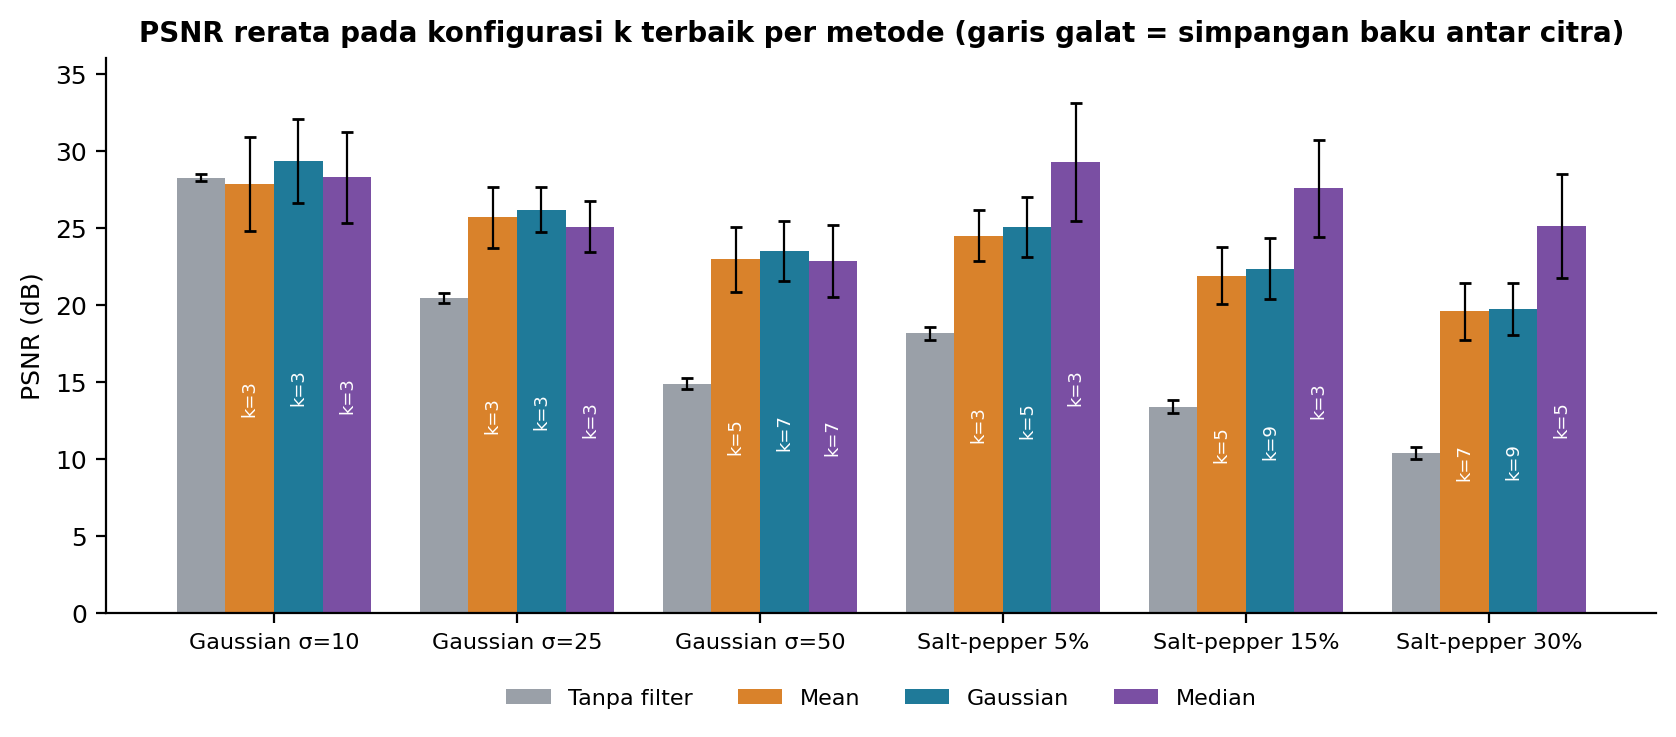

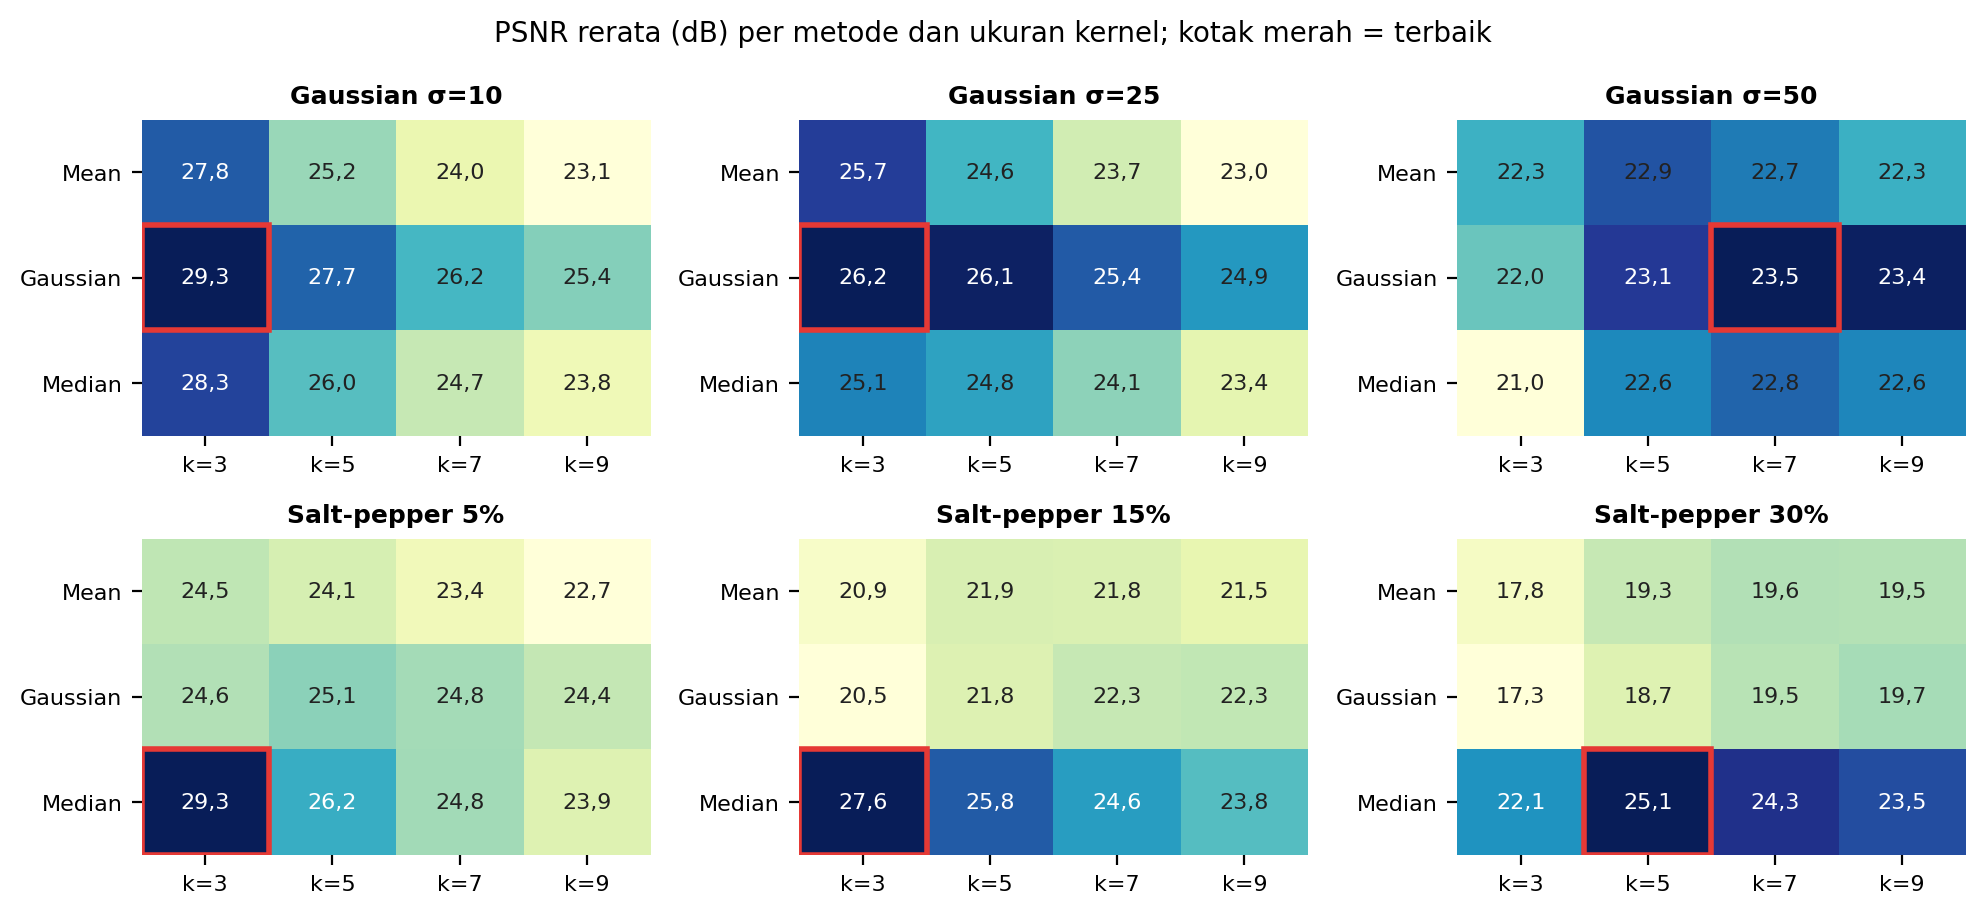

In [11]:
import pandas as pd
from IPython.display import Image, display
display(pd.read_csv('results/ringkasan_terbaik.csv')[['noise','metode','kernel','psnr','ssim','psnr_noisy','gain_psnr']].round(2))
display(Image('figures/fig07_psnr.png'))
display(Image('figures/fig09_heatmap_psnr.png'))

## 6. Hasil

In [12]:
from PIL import Image
import matplotlib.pyplot as plt
import os

def tampil(*paths):
    plt.figure(figsize=(12, 6))
    for i, p in enumerate(paths):
        full_path = p if os.path.exists(p) else os.path.join('figures', p)
        if os.path.exists(full_path):
            img = Image.open(full_path)
            plt.subplot(1, len(paths), i+1)
            plt.imshow(img)
            plt.axis('off')
            plt.title(p)
    plt.show()

### 6.1 Eksplorasi dataset
Contoh citra dan statistik: resolusi, tingkat detail, kecerahan, dan kontras.

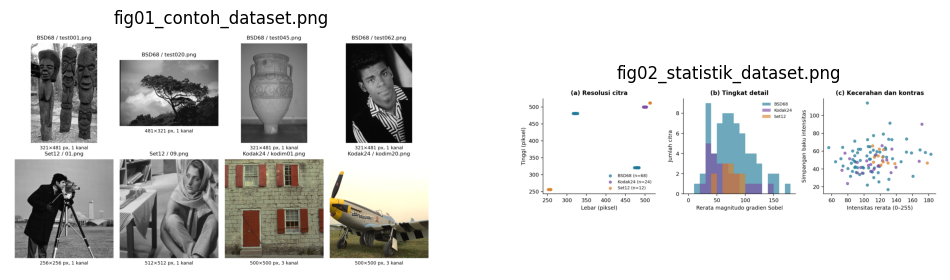

In [13]:
tampil('fig01_contoh_dataset.png', 'fig02_statistik_dataset.png')

### 6.2 Prapemrosesan
Pemisahan kanal RGB, konversi grayscale (BT.601), histogram, dan normalisasi [0,1].

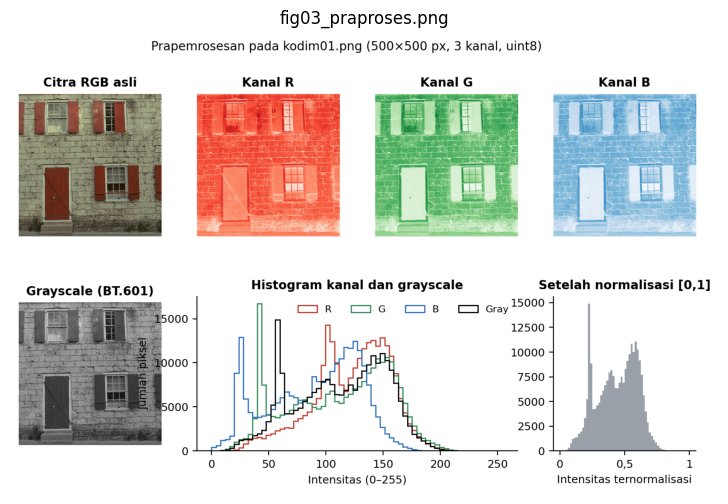

In [14]:
tampil('fig03_praproses.png')

### 6.3 Contoh noise
Set12/01.png pada enam kondisi noise (Gaussian σ=10/25/50, salt-and-pepper 5/15/30%) dan distribusi galatnya.

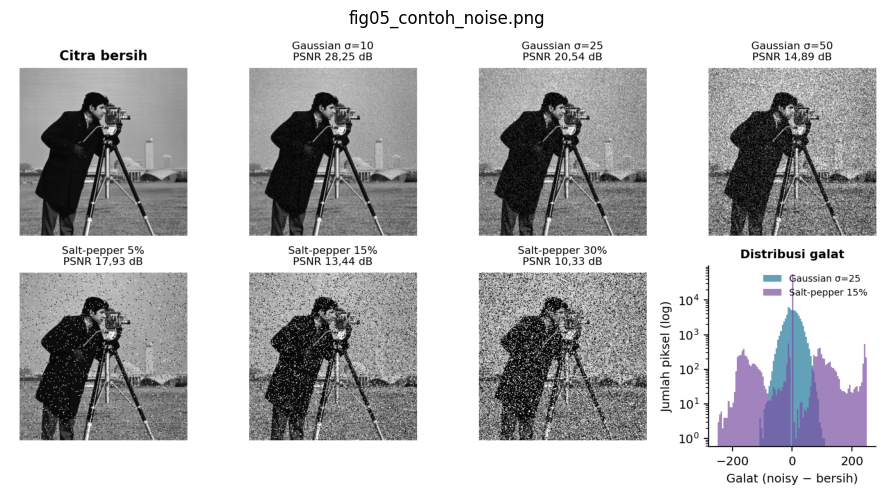

In [15]:
tampil('fig05_contoh_noise.png')

### 6.4 Hasil kualitatif
Perbandingan visual Mean, Gaussian, dan Median. Baris bawah memperbesar kotak merah.

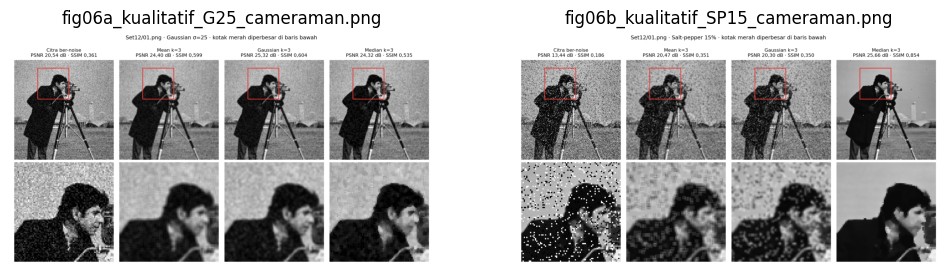

In [16]:
tampil('fig06a_kualitatif_G25_cameraman.png', 'fig06b_kualitatif_SP15_cameraman.png')

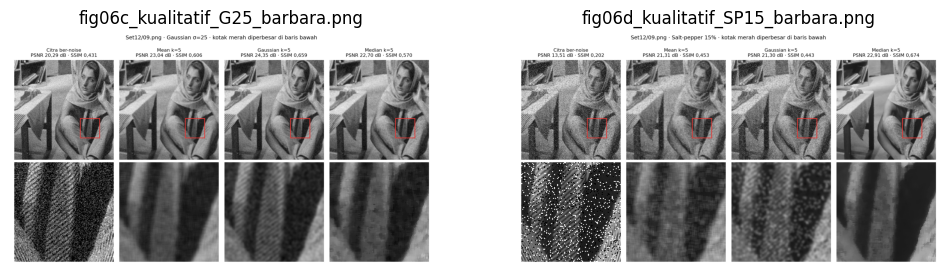

In [17]:
tampil('fig06c_kualitatif_G25_barbara.png', 'fig06d_kualitatif_SP15_barbara.png')

### 6.5 Hasil kuantitatif
Konfigurasi k terbaik per kondisi noise dan metode (rerata 104 citra).

In [18]:
pd.read_csv('results/ringkasan_terbaik.csv')[['noise','metode','kernel','psnr','psnr_sd','ssim','tepi_f1','psnr_noisy','gain_psnr']].round(3)

,noise,metode,kernel,psnr,psnr_sd,ssim,tepi_f1,psnr_noisy,gain_psnr
0,G10,Gaussian,3,29.337,2.742,0.844,0.844,28.238,1.100
1,G10,Mean,3,27.830,3.048,0.804,0.783,28.238,-0.407
2,G10,Median,3,28.264,2.930,0.790,0.828,28.238,0.026
3,G25,Gaussian,3,26.174,1.474,0.660,0.726,20.439,5.735
4,G25,Mean,3,25.679,1.984,0.648,0.763,20.439,5.240
5,G25,Median,3,25.070,1.661,0.589,0.707,20.439,4.631
6,G50,Gaussian,7,23.489,1.948,0.557,0.632,14.861,8.628
7,G50,Mean,5,22.935,2.082,0.508,0.631,14.861,8.074
8,G50,Median,7,22.812,2.339,0.486,0.547,14.861,7.951
9,SP05,Gaussian,5,25.062,1.938,0.637,0.701,18.141,6.921


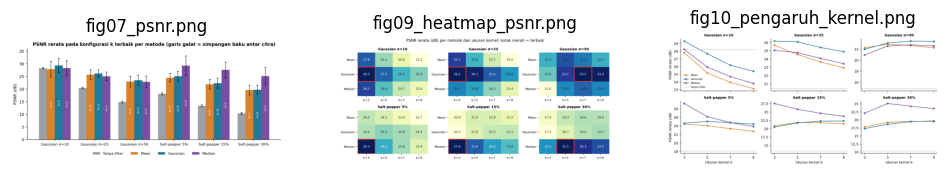

In [19]:
tampil('fig07_psnr.png', 'fig09_heatmap_psnr.png', 'fig10_pengaruh_kernel.png')

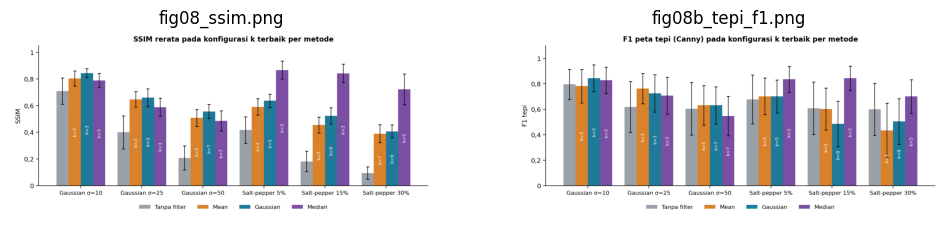

In [20]:
tampil('fig08_ssim.png', 'fig08b_tepi_f1.png')

### 6.6 Uji statistik (Wilcoxon berpasangan)

In [21]:
pd.read_csv('results/uji_wilcoxon.csv').round(4)

,noise,A,B,selisih_psnr_rerata,A_lebih_baik_pada_%,p_wilcoxon
0,G10,Median (k=3),Gaussian (k=3),-1.0733,4.8077,0.0
1,G10,Median (k=3),Mean (k=3),0.4339,79.8077,0.0
2,G10,Gaussian (k=3),Mean (k=3),1.5072,100.0000,0.0
3,G25,Median (k=3),Gaussian (k=3),-1.1039,2.8846,0.0
4,G25,Median (k=3),Mean (k=3),-0.6086,11.5385,0.0
5,G25,Gaussian (k=3),Mean (k=3),0.4953,76.9231,0.0
6,G50,Median (k=7),Gaussian (k=7),-0.6773,11.5385,0.0
7,G50,Median (k=7),Mean (k=5),-0.1230,25.0000,0.0
8,G50,Gaussian (k=7),Mean (k=5),0.5543,100.0000,0.0
9,SP05,Median (k=3),Gaussian (k=5),4.1978,100.0000,0.0


### 6.7 Waktu proses
Waktu pada 104 citra asli (OpenCV, CPU Colab) dan uji skala. Angka mutlak berbeda dari laporan karena mesinnya berbeda; yang dibandingkan adalah polanya.

In [22]:
w = pd.read_csv('results/waktu_proses.csv'); w['ms_per_mp'] = w.waktu_ms / w.mp
w.groupby(['metode','kernel'])[['waktu_ms','ms_per_mp']].mean().round(3).unstack(0)

waktu_ms                ms_per_mp               
metode Gaussian   Mean  Median  Gaussian   Mean  Median
kernel                                                 
3         0.101  0.105   0.111     0.604  0.626   0.643
5         0.178  0.120   0.669     1.042  0.712   3.901
7         0.578  0.272   9.822     3.241  1.554  55.450
9         0.758  0.275  10.719     4.216  1.568  60.522

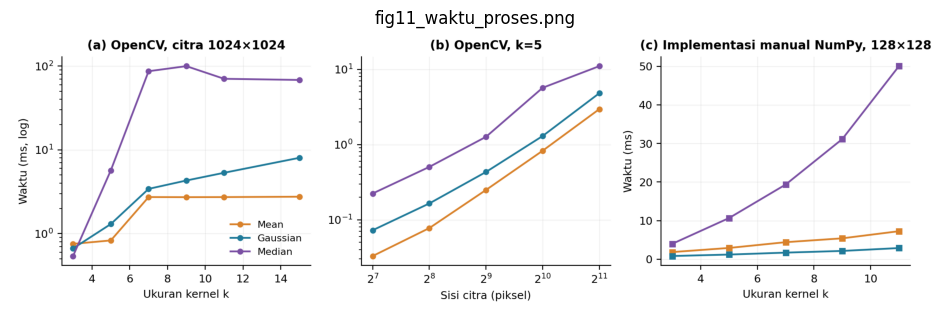

In [23]:
tampil('fig11_waktu_proses.png')

### 6.8 Pengaruh σ Gaussian dan tingkat detail citra

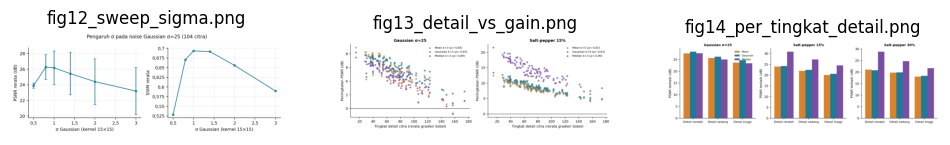

In [24]:
tampil('fig12_sweep_sigma.png', 'fig13_detail_vs_gain.png', 'fig14_per_tingkat_detail.png')

### 6.9 Analisis kegagalan
Persentase citra yang PSNR-nya turun setelah filtering, dan dua contoh kegagalan.

In [25]:
pd.read_csv('results/kegagalan_k5.csv').round(2)

,noise,metode,kernel,citra_gagal,persen_gagal,gain_rerata
0,G10,Mean,5,83,79.81,-3.04
1,G10,Gaussian,5,62,59.62,-0.54
2,G10,Median,5,75,72.12,-2.28
3,G25,Mean,5,7,6.73,4.12
4,G25,Gaussian,5,1,0.96,5.65
5,G25,Median,5,7,6.73,4.33
6,G50,Mean,5,0,0.00,8.07
7,G50,Gaussian,5,0,0.00,8.28
8,G50,Median,5,0,0.00,7.73
9,SP05,Mean,5,1,0.96,5.91


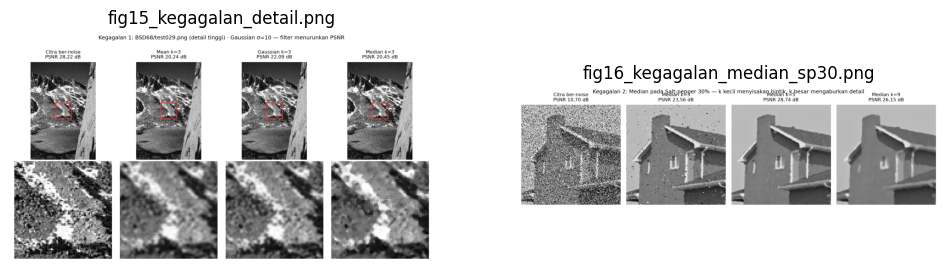

In [26]:
tampil('fig15_kegagalan_detail.png', 'fig16_kegagalan_median_sp30.png')

### 6.10 Citra berwarna (Kodak24, per kanal RGB, k=5)

,noise,metode,psnr_rgb,ssim_rgb
0,G25,Gaussian,26.526,0.676
1,G25,Mean,25.087,0.625
2,G25,Median,25.162,0.595
3,G25,Tanpa filter,20.434,0.359
4,SP15,Gaussian,21.931,0.422
5,SP15,Mean,22.161,0.437
6,SP15,Median,26.286,0.734
7,SP15,Tanpa filter,13.378,0.156


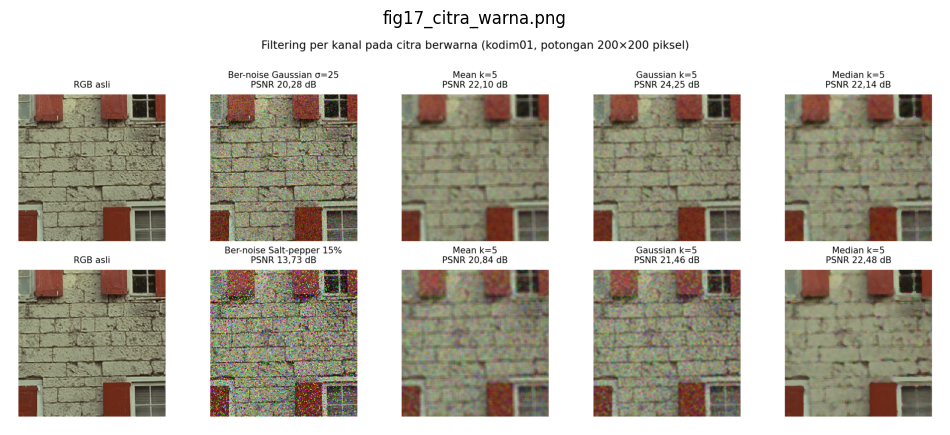

In [27]:
display(pd.read_csv('results/ringkasan_warna.csv').round(3))
tampil('fig17_citra_warna.png')

### 6.11 Verifikasi implementasi manual vs OpenCV
Selisih maksimum dalam tingkat abu (0 = identik; Gaussian ≤ 1 karena pembulatan).

In [28]:
pd.read_csv('results/verifikasi_manual.csv').groupby(['metode','kernel'])[['beda_maks','beda_rerata']].max().round(4)

beda_maks  beda_rerata
metode   kernel                        
Gaussian 3               1       0.0342
         5               1       0.0023
         7               1       0.0003
Mean     3               0       0.0000
         5               0       0.0000
         7               0       0.0000
Median   3               0       0.0000
         5               0       0.0000
         7               0       0.0000

## 7. Unduh hasil dan simpan ke Drive
Sel ini membuat dua ZIP (terunduh ke komputer), lalu menyalin seluruh folder kerja ke **My Drive/TA_PengolahanCitra125**. Jika muncul permintaan izin Drive, klik izinkan. Jalankan sel ini hanya setelah semua bagian di atas selesai.

In [29]:
import shutil, os
shutil.make_archive('hasil_TA_PengolahanCitra125', 'zip', '.', 'results')
shutil.make_archive('gambar_TA_PengolahanCitra125', 'zip', '.', 'figures')
if EN_COLAB:
    from google.colab import files
    files.download('hasil_TA_PengolahanCitra125.zip'); files.download('gambar_TA_PengolahanCitra125.zip')
    # Salin ke Google Drive (dilakukan terakhir, setelah semua hasil jadi)
    from google.colab import drive
    drive.mount('/content/drive')
    DST = '/content/drive/MyDrive/TA_PengolahanCitra125'
    shutil.copytree(BASE, DST, dirs_exist_ok=True)
    print('Tersalin ke Drive:', DST)
else:
    print('Bukan di Colab: ZIP ada di', os.getcwd())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mounted at /content/drive
Tersalin ke Drive: /content/drive/MyDrive/TA_PengolahanCitra125
